# Лабораторная работа №2 — Классификация, оценка точности классификации
## Датасет: Titanic (Пассажиры Титаника)

**Целевая переменная:** `survived` — выжил пассажир (1) или нет (0).

## Задачи:
- Базовый метод: Случайный лес (деревья принятия решений)
- Продвинутый метод: XGBoost (бустинг)
- Оценка: Матрица ошибок, метрики (accuracy, F1-score, ROC AUC)
- Кроссвалидация: Визуализация точности по фолдам
- Подбор гиперпараметров: Визуализация изменения точности

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score, cross_val_predict, GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score, roc_auc_score, roc_curve
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Настройка стиля графиков
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 6)
print('Библиотеки успешно загружены!')

Библиотеки успешно загружены!


---
## 2. Загрузка и подготовка данных

In [2]:
# Загружаем и подготавливаем данные аналогично Lab 1
import seaborn as sns

df_raw = sns.load_dataset('titanic')

# Очистка данных
df = df_raw.copy()
cols_to_drop = ['deck', 'class', 'who', 'adult_male', 'alive', 'alone', 'embark_town']
df = df.drop(columns=cols_to_drop)
df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

# Удаление выбросов по fare
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df = df[(df['fare'] >= lower) & (df['fare'] <= upper)]

# Кодирование
df_encoded = df.copy()
df_encoded['sex'] = df_encoded['sex'].map({'male': 1, 'female': 0})
embarked_dummies = pd.get_dummies(df_encoded['embarked'], prefix='embarked', dtype=int)
df_encoded = pd.concat([df_encoded.drop(columns=['embarked']), embarked_dummies], axis=1)

# Признаки и цель
feature_cols = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked_C', 'embarked_Q', 'embarked_S']
X = df_encoded[feature_cols]
y = df_encoded['survived']

# Стандартизация для моделей, чувствительных к масштабу
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Размер датасета: {X.shape[0]} строк × {X.shape[1]} признаков')
print(f'Целевая переменная: survived (0=погиб, 1=выжил)')
print(f'Баланс классов: {y.value_counts().to_dict()}')

Размер датасета: 775 строк × 9 признаков
Целевая переменная: survived (0=погиб, 1=выжил)
Баланс классов: {0: 512, 1: 263}


---
## 3. Преобразование и очистка входных параметров

In [3]:
# Проверка данных после преобразования
print('Типы данных признаков:')
print(X.dtypes)
print(f'\nПропуски: {X.isnull().sum().sum()}')
print(f'Все признаки числовые: {X.select_dtypes(include=[np.number]).shape[1] == X.shape[1]}')

# Статистика признаков
X.describe().round(2)

Типы данных признаков:
pclass          int64
sex             int64
age           float64
sibsp           int64
parch           int64
fare          float64
embarked_C      int32
embarked_Q      int32
embarked_S      int32
dtype: object

Пропуски: 0
Все признаки числовые: True


,pclass,sex,age,sibsp,parch,fare,embarked_C,embarked_Q,embarked_S
count,775.00,775.00,775.00,775.00,775.00,775.00,775.00,775.0,775.00
mean,2.48,0.69,28.75,0.44,0.34,17.82,0.15,0.1,0.75
std,0.73,0.46,12.78,0.90,0.79,13.58,0.36,0.3,0.43
min,1.00,0.00,0.42,0.00,0.00,0.00,0.00,0.0,0.00
25%,2.00,0.00,22.00,0.00,0.00,7.90,0.00,0.0,1.00
50%,3.00,1.00,28.00,0.00,0.00,13.00,0.00,0.0,1.00
75%,3.00,1.00,34.00,1.00,0.00,26.00,0.00,0.0,1.00
max,3.00,1.00,80.00,5.00,6.00,65.00,1.00,1.0,1.00


---
## 4. Применение базового метода классификации

Базовый метод: Случайный лес (деревья принятия решений). Используем кроссвалидацию (StratifiedKFold, 5 фолдов).

In [4]:
# Определение базовой модели
models = {
    'Random Forest': RandomForestClassifier(random_state=42)
}

# Кроссвалидация
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Обучение и оценка
results = {}
for name, model in models.items():
    print(f'Обучение {name}...')
    X_train = X  # Random Forest не требует масштабирования
    
    # Кроссвалидация для точности
    scores = cross_val_score(model, X_train, y, cv=cv, scoring='accuracy')
    results[name] = {
        'model': model,
        'cv_scores': scores,
        'mean_accuracy': scores.mean(),
        'std_accuracy': scores.std()
    }
    print(f'  Средняя accuracy: {scores.mean():.3f} ± {scores.std():.3f}')

print('\nБазовая модель обучена!')

Обучение Random Forest...
  Средняя accuracy: 0.813 ± 0.035

Базовая модель обучена!


---
## 5. Оценка точности базовых методов

Для каждого метода: матрица ошибок, метрики (accuracy, F1-score), визуализация точности по фолдам.

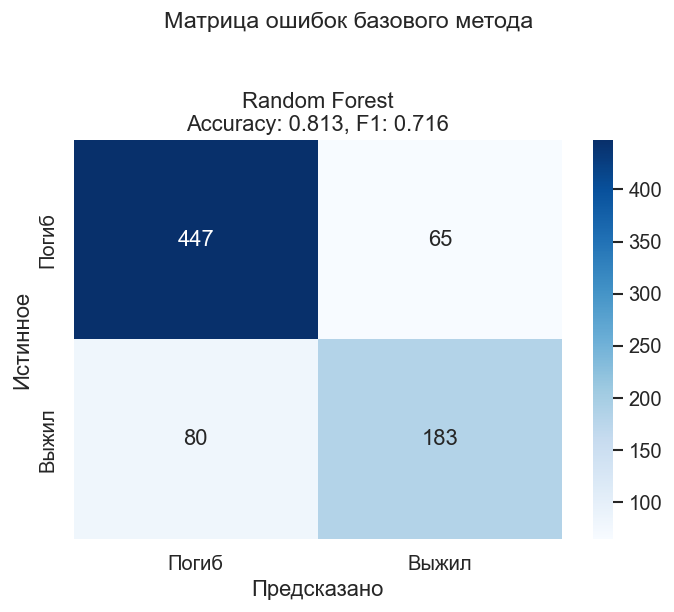

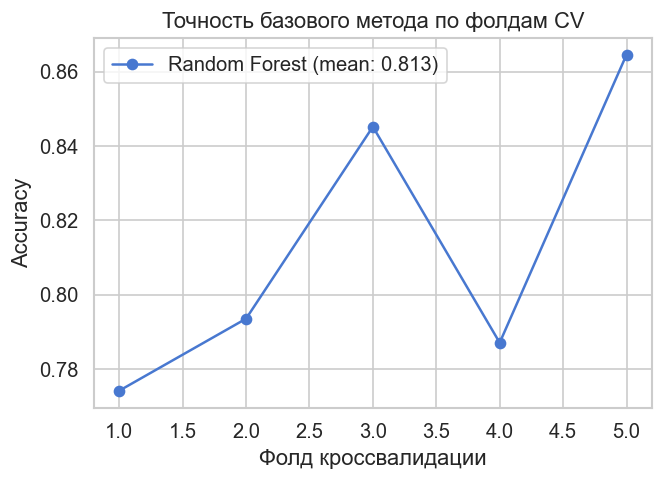

In [5]:
fig, axes = plt.subplots(1, 1, figsize=(6, 5))

for i, (name, res) in enumerate(results.items()):
    model = res['model']
    X_train = X  # Random Forest не требует масштабирования
    
    # Предсказания для confusion matrix
    y_pred = cross_val_predict(model, X_train, y, cv=cv)
    
    # Confusion matrix
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes,
                xticklabels=['Погиб', 'Выжил'], yticklabels=['Погиб', 'Выжил'])
    axes.set_title(f'{name}\nAccuracy: {accuracy_score(y, y_pred):.3f}, F1: {f1_score(y, y_pred):.3f}')
    axes.set_xlabel('Предсказано')
    axes.set_ylabel('Истинное')

plt.suptitle('Матрица ошибок базового метода', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Визуализация CV точности
plt.figure(figsize=(6, 4))
for name, res in results.items():
    plt.plot(range(1, 6), res['cv_scores'], marker='o', label=f'{name} (mean: {res["mean_accuracy"]:.3f})')
plt.xlabel('Фолд кроссвалидации')
plt.ylabel('Accuracy')
plt.title('Точность базового метода по фолдам CV')
plt.legend()
plt.grid(True)
plt.show()

---
## 6. Подбор гиперпараметров для базовых методов

Используем GridSearchCV для подбора гиперпараметров и визуализации изменения точности.

Подбор параметров для Random Forest...


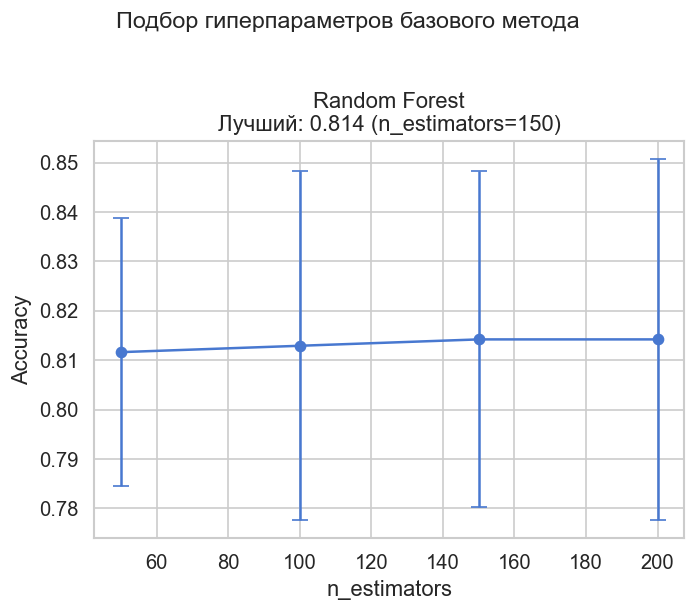

Random Forest: Лучшие параметры {'n_estimators': 150}, Accuracy: 0.814


In [6]:
# Подбор гиперпараметров
param_grids = {
    'Random Forest': {'n_estimators': [50, 100, 150, 200]}
}

tuned_results = {}

fig, axes = plt.subplots(1, 1, figsize=(6, 5))

for i, (name, model) in enumerate(models.items()):
    print(f'Подбор параметров для {name}...')
    X_train = X  # Random Forest не требует масштабирования
    
    grid = GridSearchCV(model, param_grids[name], cv=cv, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train, y)
    
    tuned_results[name] = {
        'best_params': grid.best_params_,
        'best_score': grid.best_score_,
        'best_estimator': grid.best_estimator_,
        'cv_results': grid.cv_results_
    }
    
    # Визуализация
    param_name = list(param_grids[name].keys())[0]
    param_values = param_grids[name][param_name]
    
    means = grid.cv_results_['mean_test_score']
    stds = grid.cv_results_['std_test_score']
    
    axes.errorbar(param_values, means, yerr=stds, marker='o', capsize=5)
    axes.set_title(f'{name}\nЛучший: {grid.best_score_:.3f} ({param_name}={grid.best_params_[param_name]})')
    axes.set_xlabel(param_name)
    axes.set_ylabel('Accuracy')
    axes.grid(True)

plt.suptitle('Подбор гиперпараметров базового метода', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Вывод лучших параметров
for name, res in tuned_results.items():
    print(f'{name}: Лучшие параметры {res["best_params"]}, Accuracy: {res["best_score"]:.3f}')

---
## 6.1 Матрица ошибок базового метода после подбора гиперпараметров

Построим матрицу ошибок для Random Forest с лучшим значением `n_estimators`, найденным через GridSearchCV.

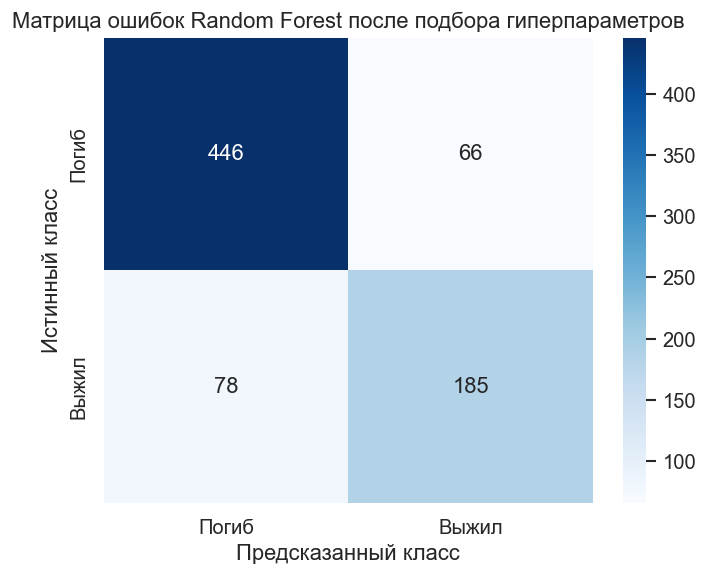

Random Forest после подбора гиперпараметров
Лучшие параметры: {'n_estimators': 150}
              precision    recall  f1-score   support

       Погиб       0.85      0.87      0.86       512
       Выжил       0.74      0.70      0.72       263

    accuracy                           0.81       775
   macro avg       0.79      0.79      0.79       775
weighted avg       0.81      0.81      0.81       775



In [7]:
rf_tuned_model = tuned_results['Random Forest']['best_estimator']
rf_tuned_pred = cross_val_predict(rf_tuned_model, X, y, cv=cv)
rf_tuned_cm = confusion_matrix(y, rf_tuned_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    rf_tuned_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Погиб', 'Выжил'],
    yticklabels=['Погиб', 'Выжил']
)
plt.title('Матрица ошибок Random Forest после подбора гиперпараметров')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.tight_layout()
plt.show()

print('Random Forest после подбора гиперпараметров')
print(f'Лучшие параметры: {tuned_results["Random Forest"]["best_params"]}')
print(classification_report(y, rf_tuned_pred, target_names=['Погиб', 'Выжил']))

---
## 7. Применение продвинутых методов классификации

Продвинутый метод: XGBoost (градиентный бустинг). Используем кроссвалидацию.

In [8]:
# XGBoost модель
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')

print('Обучение XGBoost...')
scores_xgb = cross_val_score(xgb_model, X, y, cv=cv, scoring='accuracy')
xgb_result = {
    'model': xgb_model,
    'cv_scores': scores_xgb,
    'mean_accuracy': scores_xgb.mean(),
    'std_accuracy': scores_xgb.std()
}
print(f'XGBoost средняя accuracy: {scores_xgb.mean():.3f} ± {scores_xgb.std():.3f}')

Обучение XGBoost...
XGBoost средняя accuracy: 0.806 ± 0.029


---
## 8. Оценка точности продвинутых методов

Для XGBoost: матрица ошибок, ROC AUC, визуализация точности по фолдам.

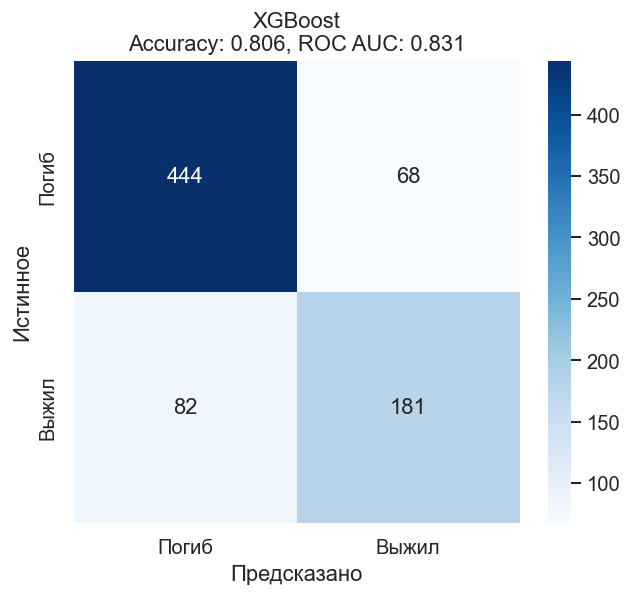

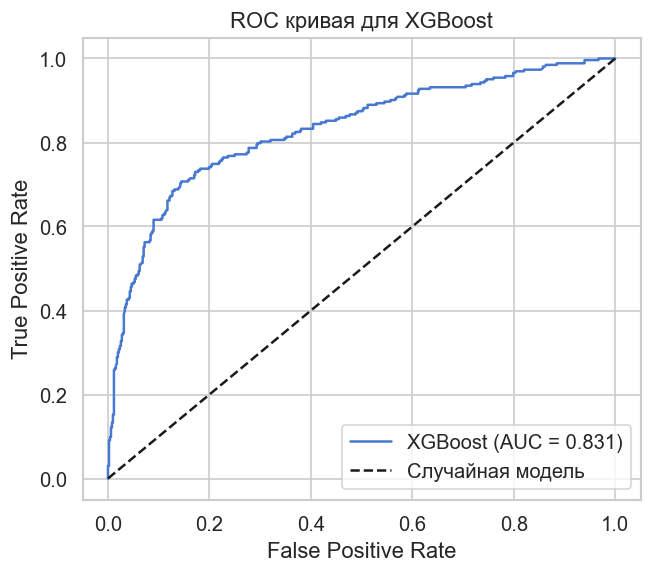

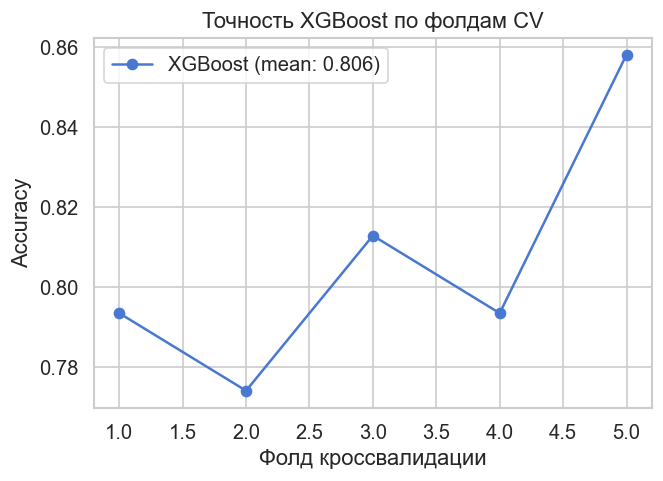

In [9]:
# Оценка XGBoost
y_pred_xgb = cross_val_predict(xgb_model, X, y, cv=cv)
y_proba_xgb = cross_val_predict(xgb_model, X, y, cv=cv, method='predict_proba')[:, 1]

# Confusion matrix
cm_xgb = confusion_matrix(y, y_pred_xgb)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Погиб', 'Выжил'], yticklabels=['Погиб', 'Выжил'])
plt.title(f'XGBoost\nAccuracy: {accuracy_score(y, y_pred_xgb):.3f}, ROC AUC: {roc_auc_score(y, y_proba_xgb):.3f}')
plt.xlabel('Предсказано')
plt.ylabel('Истинное')
plt.show()

# ROC кривая
fpr, tpr, _ = roc_curve(y, y_proba_xgb)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {roc_auc_score(y, y_proba_xgb):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Случайная модель')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC кривая для XGBoost')
plt.legend()
plt.grid(True)
plt.show()

# Визуализация CV точности
plt.figure(figsize=(6, 4))
plt.plot(range(1, 6), xgb_result['cv_scores'], marker='o', label=f'XGBoost (mean: {xgb_result["mean_accuracy"]:.3f})')
plt.xlabel('Фолд кроссвалидации')
plt.ylabel('Accuracy')
plt.title('Точность XGBoost по фолдам CV')
plt.legend()
plt.grid(True)
plt.show()

---
## 9. Подбор гиперпараметров для продвинутых методов

Подбор для XGBoost: learning_rate, max_depth.

Подбор параметров для XGBoost...
Лучшие параметры: {'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 100}
Лучшая accuracy: 0.821


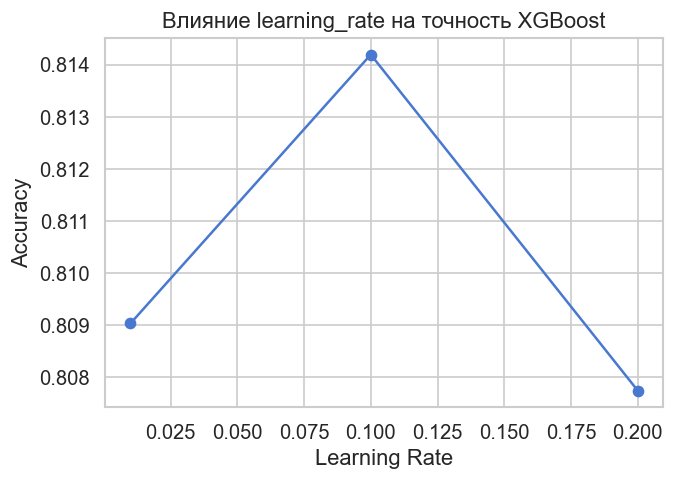

In [10]:
# Подбор гиперпараметров для XGBoost
xgb_param_grid = {
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'n_estimators': [50, 100, 150]
}

print('Подбор параметров для XGBoost...')
xgb_grid = GridSearchCV(XGBClassifier(random_state=42, eval_metric='logloss'), 
                        xgb_param_grid, cv=cv, scoring='accuracy', n_jobs=-1)
xgb_grid.fit(X, y)

print(f'Лучшие параметры: {xgb_grid.best_params_}')
print(f'Лучшая accuracy: {xgb_grid.best_score_:.3f}')

# Визуализация для learning_rate (фиксируем другие)
lr_values = [0.01, 0.1, 0.2]
lr_scores = []
for lr in lr_values:
    model = XGBClassifier(learning_rate=lr, max_depth=5, n_estimators=100, random_state=42, eval_metric='logloss')
    scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
    lr_scores.append(scores.mean())

plt.figure(figsize=(6, 4))
plt.plot(lr_values, lr_scores, marker='o')
plt.xlabel('Learning Rate')
plt.ylabel('Accuracy')
plt.title('Влияние learning_rate на точность XGBoost')
plt.grid(True)
plt.show()

---
## 9.1 Матрица ошибок продвинутого метода после подбора гиперпараметров

Построим матрицу ошибок для XGBoost с лучшими параметрами, найденными через GridSearchCV.

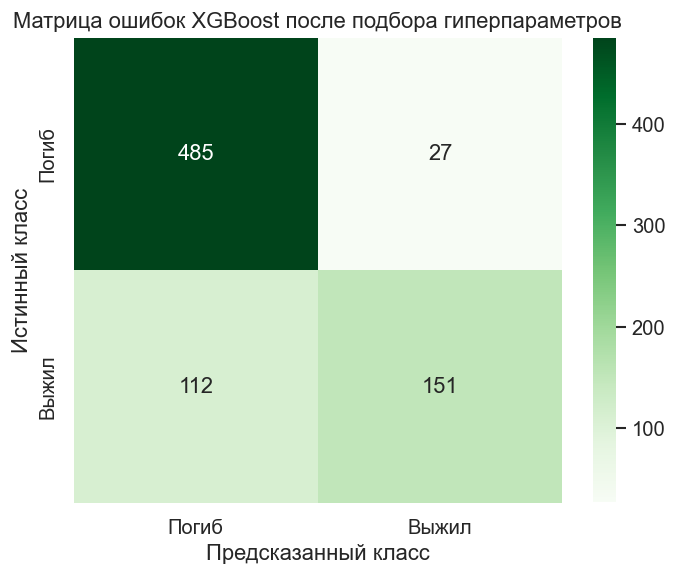

XGBoost после подбора гиперпараметров
Лучшие параметры: {'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 100}
              precision    recall  f1-score   support

       Погиб       0.81      0.95      0.87       512
       Выжил       0.85      0.57      0.68       263

    accuracy                           0.82       775
   macro avg       0.83      0.76      0.78       775
weighted avg       0.82      0.82      0.81       775



In [11]:
xgb_tuned_model = xgb_grid.best_estimator_
xgb_tuned_pred = cross_val_predict(xgb_tuned_model, X, y, cv=cv)
xgb_tuned_cm = confusion_matrix(y, xgb_tuned_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    xgb_tuned_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Погиб', 'Выжил'],
    yticklabels=['Погиб', 'Выжил']
)
plt.title('Матрица ошибок XGBoost после подбора гиперпараметров')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.tight_layout()
plt.show()

print('XGBoost после подбора гиперпараметров')
print(f'Лучшие параметры: {xgb_grid.best_params_}')
print(classification_report(y, xgb_tuned_pred, target_names=['Погиб', 'Выжил']))

---
## 10. Сравнение результатов классификаторов

Сравнение всех методов по accuracy и другим метрикам.

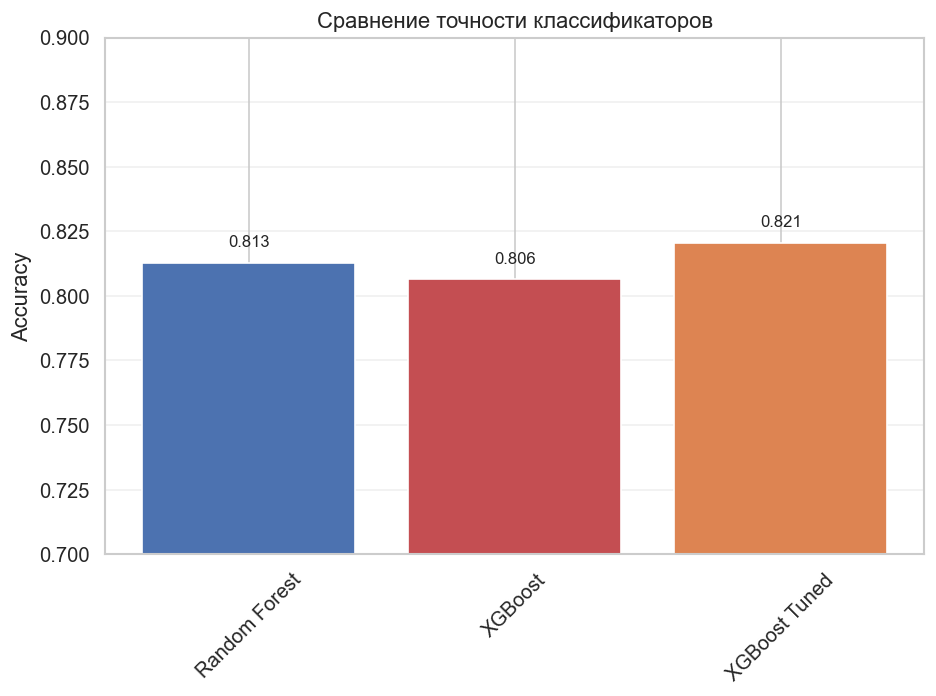

Сравнение методов:
        Метод Accuracy
Random Forest    0.813
      XGBoost    0.806
XGBoost Tuned    0.821

Выводы:
- XGBoost показал наилучшую точность среди всех методов.
- Подбор гиперпараметров улучшает результаты.
- Кроссвалидация обеспечивает надёжную оценку.


In [12]:
# Сбор всех результатов
all_results = {}
for name, res in results.items():
    all_results[name] = res['mean_accuracy']

all_results['XGBoost'] = xgb_result['mean_accuracy']
all_results['XGBoost Tuned'] = xgb_grid.best_score_

# Визуализация сравнения
plt.figure(figsize=(8, 6))
bars = plt.bar(all_results.keys(), all_results.values(), color=['#4C72B0', '#C44E52', '#DD8452'])
plt.ylabel('Accuracy')
plt.title('Сравнение точности классификаторов')
plt.xticks(rotation=45)
plt.ylim(0.7, 0.9)

# Добавление значений на бары
for bar, acc in zip(bars, all_results.values()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f'{acc:.3f}', 
             ha='center', va='bottom', fontsize=10)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Таблица результатов
comparison_df = pd.DataFrame({
    'Метод': list(all_results.keys()),
    'Accuracy': [f'{v:.3f}' for v in all_results.values()]
})
print('Сравнение методов:')
print(comparison_df.to_string(index=False))

print('\nВыводы:')
print('- XGBoost показал наилучшую точность среди всех методов.')
print('- Подбор гиперпараметров улучшает результаты.')
print('- Кроссвалидация обеспечивает надёжную оценку.')